# 2. Atmosphere scenarios

Every showcase target offers five scenarios. They are presets of the parametric
model (`lazuli_exo.presets`), evaluated at the planet's registry values, so a
scenario is a handful of atmosphere parameters rather than a separate table.

| Scenario | Parameters | What it represents |
|---|---|---|
| `clear` | solar metallicity, no deck, no haze | Full-amplitude molecular features, the optimistic case |
| `cloudy` | gray deck at 1 mbar | An opaque deck truncating the features from below |
| `hazy` | haze 100x H<sub>2</sub> Rayleigh at 0.35 µm, slope −6 | A scattering haze steepening the blue continuum |
| `high_metallicity` | 100x solar | Higher mean molecular weight, so a smaller scale height |
| `flat` | gray deck at 10 nbar | A featureless (R<sub>p</sub>/R<sub>s</sub>)<sup>2</sup> line |

All five use C/O = 0.55, the equilibrium-chemistry mean molecular weight and a
single isothermal T = T<sub>eq</sub> layer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__version__ if hasattr(lazuli_exo, "__version__") else "(dev)")

lazuli_exo (dev)


## The recorded settings

The presets are code, and the parameters end up in `obs.meta["params"]`, so you
can read back exactly what was run rather than trusting the table above.

In [2]:
from lazuli_exo import presets

PLANET = "WASP-39 b"
keys = ("log_met", "c_to_o", "mu", "log_P_cloud_bar", "log_a_haze", "haze_slope")

print(f"{'scenario':18s}" + "".join(f"{k:>16s}" for k in keys))
for s in lazuli_exo.list_scenarios(PLANET):
    p = lazuli_exo.observe(PLANET, scenario=s).meta["params"]
    assert {k: p[k] for k in keys} == {**presets.SCENARIO_PARAMS[s], "mu": None}
    print(f"{s:18s}" + "".join(f"{str(p[k]):>16s}" for k in keys))

scenario                   log_met          c_to_o              mu log_P_cloud_bar      log_a_haze      haze_slope


clear                          0.0            0.55            None            None            None            -4.0


cloudy                         0.0            0.55            None            -3.0            None            -4.0
flat                           0.0            0.55            None            -8.0            None            -4.0


hazy                           0.0            0.55            None            None             2.0            -6.0
high_metallicity               2.0            0.55            None            None            None            -4.0


## The four physical scenarios side by side

`obs.plot(ax=ax, show_points=False)` draws only the native-resolution model, so
several scenarios overlay on one Axes. `clear` has the deepest molecular bands;
the deck in `cloudy` clips them from below; `hazy` adds a rising blue slope;
`high_metallicity` compresses everything because the mean molecular weight, and
with it the scale height, has changed.

One convention to keep in mind when reading the overlay: `R_p` is the
band-median transit radius, so every scenario is pinned to the same depth at
mid-band. A haze or a deck therefore raises the blue end and lowers the red end
relative to `clear`, instead of sitting above it everywhere.

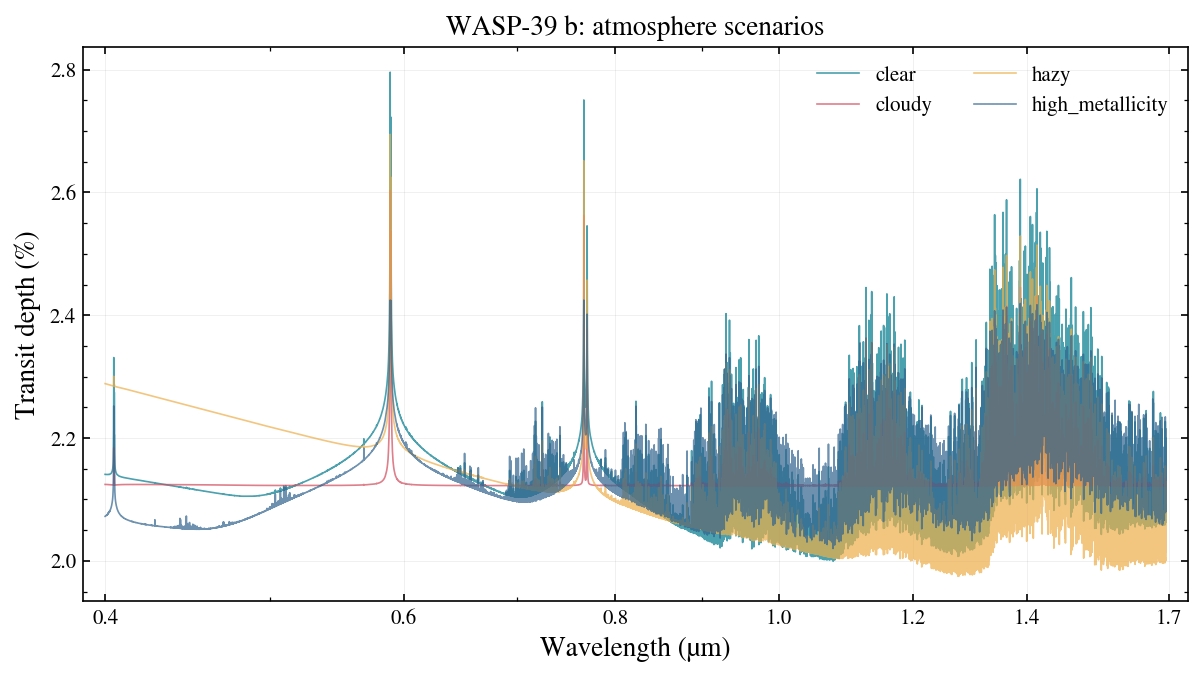

In [3]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for s in ["clear", "cloudy", "hazy", "high_metallicity"]:
    lazuli_exo.observe(PLANET, scenario=s, R=100).plot(ax=ax, show_points=False)
ax.set_title(f"{PLANET}: atmosphere scenarios")
ax.legend(frameon=False, ncol=2)
plt.show()

## The `flat` baseline

`flat` puts the deck above every line core, which leaves a constant
(R<sub>p</sub>/R<sub>s</sub>)<sup>2</sup> line to within a ppm. It is what the
template S/N is measured against, so `detect()` on it returns almost exactly
zero.

In [4]:
obs_clear = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1)
obs_flat = lazuli_exo.observe(PLANET, scenario="flat", n_transits=1)

snr_clear = obs_clear.detect()["template_snr_diagonal"]
snr_flat = obs_flat.detect()["template_snr_diagonal"]

print(f"flat_depth (geometric):   {obs_flat.flat_depth * 100:.4f} %")
print(f"flat model spread:        {np.ptp(obs_flat.depth) * 1e6:.3g} ppm")
print()
print(f"template S/N, clear: {snr_clear:8.2f}")
print(f"template S/N, flat:  {snr_flat:8.4f}")

assert snr_flat < 0.01, "the flat baseline must carry no template signal"
assert snr_clear > 50 * max(snr_flat, 1e-6)
print("\nOK: flat is featureless, clear is not.")

flat_depth (geometric):   2.1228 %
flat model spread:        0.0647 ppm

template S/N, clear:    68.65
template S/N, flat:    0.0012

OK: flat is featureless, clear is not.


## Feature amplitude across scenarios and targets

The same comparison for four targets spanning the sample: a hot Saturn, a warm
Neptune, a sub-Neptune and a temperate terrestrial. This is one transit each, so
the absolute values depend on host brightness as much as on the atmosphere.

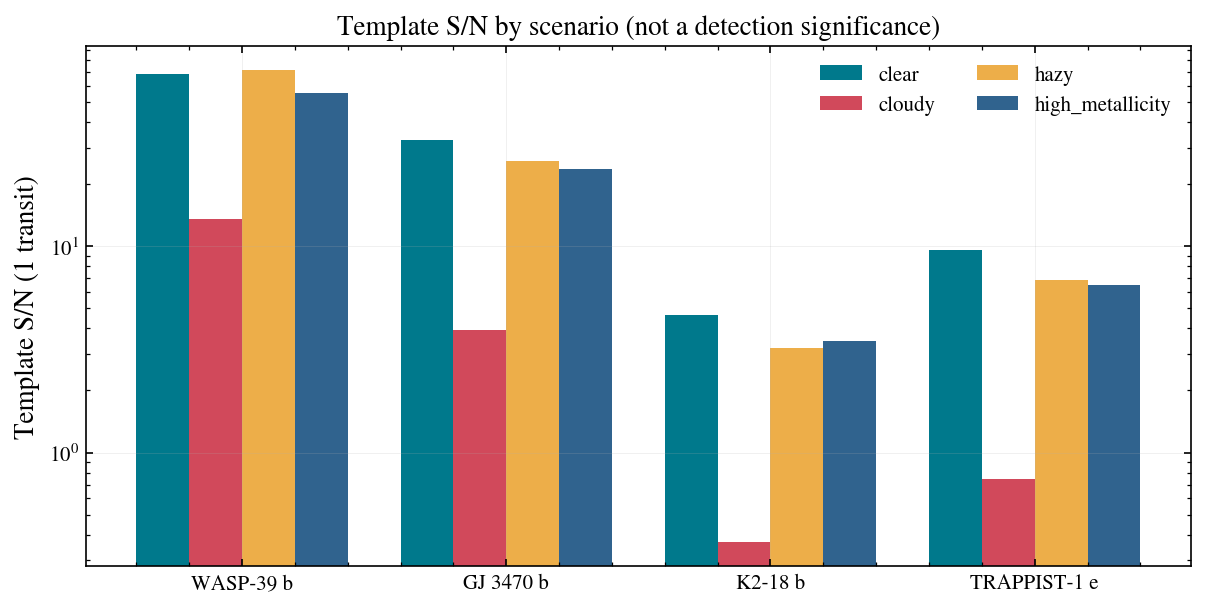

WASP-39 b      clear=   68.65  cloudy=   13.55  hazy=   71.74  high_metallicity=   55.19
GJ 3470 b      clear=   32.65  cloudy=    3.91  hazy=   25.86  high_metallicity=   23.65
K2-18 b        clear=    4.67  cloudy=    0.37  hazy=    3.22  high_metallicity=    3.48
TRAPPIST-1 e   clear=    9.62  cloudy=    0.75  hazy=    6.85  high_metallicity=    6.48


In [5]:
TARGETS = ["WASP-39 b", "GJ 3470 b", "K2-18 b", "TRAPPIST-1 e"]
PHYSICAL = ["clear", "cloudy", "hazy", "high_metallicity"]

snr = {t: [lazuli_exo.observe(t, scenario=s, n_transits=1)
           .detect()["template_snr_diagonal"] for s in PHYSICAL]
       for t in TARGETS}

fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(TARGETS))
width = 0.2
for i, s in enumerate(PHYSICAL):
    ax.bar(x + (i - 1.5) * width, [snr[t][i] for t in TARGETS],
           width, label=s)

ax.set_xticks(x)
ax.set_xticklabels(TARGETS)
ax.set_yscale("log")
ax.set_ylabel("Template S/N (1 transit)")
ax.set_title("Template S/N by scenario (not a detection significance)")
ax.legend(frameon=False, ncol=2)
plt.show()

for t in TARGETS:
    print(f"{t:14s} " + "  ".join(f"{s}={v:8.2f}"
                                  for s, v in zip(PHYSICAL, snr[t])))

Two orderings hold for every target: the deck mutes the features, and higher
metallicity shrinks the scale height, so both score below `clear`.

`hazy` is the interesting one. On WASP-39 b it scores above `clear`, and on the
cooler targets it does not. That is a good illustration of what the statistic
measures. The template norm rewards any deviation from a flat line, and a haze
contributes a steep Rayleigh-like slope across the blue half of the band. A
smooth continuum slope is a large departure from flat even though it carries no
molecular information. Read `template_snr_diagonal` as "how much structure is
there", never as "how much atmosphere is detectable".

In [6]:
for t in TARGETS:
    v = dict(zip(PHYSICAL, snr[t]))
    assert v["clear"] > v["cloudy"], t
    assert v["clear"] > v["high_metallicity"], t
print("OK: clear > cloudy and clear > high_metallicity for every target.\n")

print(f"{'planet':14s}{'clear':>10s}{'hazy':>10s}{'hazy/clear':>13s}")
for t in TARGETS:
    v = dict(zip(PHYSICAL, snr[t]))
    print(f"{t:14s}{v['clear']:10.2f}{v['hazy']:10.2f}"
          f"{v['hazy'] / v['clear']:13.2f}")

OK: clear > cloudy and clear > high_metallicity for every target.

planet             clear      hazy   hazy/clear
WASP-39 b          68.65     71.74         1.04
GJ 3470 b          32.65     25.86         0.79
K2-18 b             4.67      3.22         0.69
TRAPPIST-1 e        9.62      6.85         0.71


## Which bands carry the signal

Splitting the same statistic by the fixed wavelength masks shows where in the
band the scenarios differ. The masks overlap and every species is mixed
together, so read these as "where the spectrum has structure".

In [7]:
from lazuli_exo.detect import BAND_MASKS

mols = sorted(BAND_MASKS)

print(f"{PLANET}, 1 transit, band-restricted template norms\n")
print(f"{'scenario':18s}" + "".join(f"{m:>10s}" for m in mols))
for s in PHYSICAL + ["flat"]:
    bands = lazuli_exo.observe(PLANET, scenario=s,
                               n_transits=1).detect()["band_snr"]
    print(f"{s:18s}" + "".join(f"{bands[m]:10.2f}" for m in mols))

WASP-39 b, 1 transit, band-restricted template norms

scenario                 CH4       CO2       H2O         K        Na
clear                  18.80     26.00     46.62     15.20     22.66
cloudy                  2.35      7.00     11.22      2.07      5.00


hazy                   21.84     20.91     31.47     10.47     19.35
high_metallicity       17.08     20.85     39.64      6.83     13.74
flat                    0.00      0.00      0.00      0.00      0.00


Going from `clear` to `hazy` on WASP-39 b, the H2O, Na, K and CO2 norms drop as
the molecular bands are partly veiled, and yet the total goes up. The extra
structure lives outside every mask, in the blue continuum below 0.575 µm where
the haze slope is steepest and no band mask reaches. The cell below splits the
total into the part inside any mask and the part outside all of them.

In [8]:
def chi2_split(obs):
    """Template chi2 inside any band mask vs. outside all of them."""
    w = 1.0 / obs.depth_err ** 2
    dbar = np.sum(w * obs.depth) / np.sum(w)
    chi2 = w * (obs.depth - dbar) ** 2

    in_mask = np.zeros(obs.wavelength.shape, dtype=bool)
    for spans in BAND_MASKS.values():
        for lo, hi in spans:
            in_mask |= (obs.wavelength >= lo) & (obs.wavelength <= hi)
    return np.sqrt(chi2[in_mask].sum()), np.sqrt(chi2[~in_mask].sum())


print(f"{'scenario':18s}{'total S/N':>11s}{'in-mask':>10s}"
      f"{'out-of-mask':>14s}{'out fraction':>14s}")
rows = {}
for s in ["clear", "hazy"]:
    o = lazuli_exo.observe(PLANET, scenario=s, n_transits=1)
    inside, outside = chi2_split(o)
    total = o.detect()["template_snr_diagonal"]
    rows[s] = (outside / total) ** 2
    print(f"{s:18s}{total:11.2f}{inside:10.2f}{outside:14.2f}"
          f"{rows[s]:14.2f}")
assert rows["hazy"] > rows["clear"], "the haze adds out-of-mask structure"

scenario            total S/N   in-mask   out-of-mask  out fraction
clear                   68.65     56.46         39.05          0.32


hazy                    71.74     43.98         56.68          0.62


## The cold-planet temperature floor

The equilibrium-chemistry grid behind the model starts at 300 K. Three targets
sit below it: their chemistry is evaluated at 300 K while the scale height uses
the true T<sub>eq</sub>. `meta["atmosphere"]` records both temperatures and the
flag, so you never have to guess.

In [9]:
import warnings

print(f"{'planet':14s}{'T_eq (K)':>10s}{'T_chem (K)':>12s}  clamped")
with warnings.catch_warnings():
    # one bright host warns about residual detector saturation;
    # notebook 05 covers what that means
    warnings.simplefilter("ignore", UserWarning)
    for p in lazuli_exo.list_planets():
        m = lazuli_exo.observe(p, scenario="clear", n_transits=1).meta
        a = m["atmosphere"]
        flag = "  <-- clamped" if a["T_clamped"] else ""
        print(f"{p:14s}{m['params']['T_eq_K']:10.0f}{a['T_chem_K']:12.0f}{flag}")

planet          T_eq (K)  T_chem (K)  clamped
GJ 1214 b            567         567
GJ 3470 b            594         594
HAT-P-11 b           838         838
HD 189733 b         1209        1209
HD 209458 b         1459        1459
K2-18 b              284         300  <-- clamped
LHS 1140 b           226         300  <-- clamped
TOI-270 d            383         383


TRAPPIST-1 e         250         300  <-- clamped
WASP-107 b           736         736
WASP-12 b           2601        2601
WASP-121 b          2409        2409
WASP-39 b           1166        1166
WASP-96 b           1285        1285


## Summary

- Four physical scenarios (`clear`, `cloudy`, `hazy`, `high_metallicity`) plus a
  featureless `flat` baseline, all presets of one parametric model, with the
  parameters recorded in `meta["params"]`.
- `clear` maximizes feature amplitude; a deck truncates it, high metallicity
  compresses it.
- `flat` carries no template signal by construction; it is the reference the
  statistic is measured against.
- A haze can raise the template S/N through continuum slope alone, which is the
  clearest reminder that the statistic measures structure, not molecules.
- Sub-300 K targets use 300 K chemistry and are flagged with `T_clamped`.

Next: [transits and binning](03_transits_and_binning.ipynb), how `n_transits`
and `R` trade against each other.